# ДЗ 3. Дообучение BERT для распознавания именованных сущностей (NER)

---

### Зачем это нужно

Извлечение именованных сущностей (Named Entity Recognition, NER) —  людей, организаций, географических объектов и других сущностей —  это один из первых шагов превращения неструктурированного текста в структурированные данные. На этой задаче строится поиск по сущностям, аналитика, извлечение информации и базы знаний.

Мы разобрали, как предобученную модель BERT можно адаптировать к новой задаче, заменив выходную классификационную голову и дообучив модель на размеченных данных. В этом домашнем задании вы проделаете этот процесс самостоятельно: возьмете предобученный русскоязычный BERT и дообучите его для задачи разметки последовательностей.

Главный результат работы —  не достижение высоких значений метрики, а корректная и осмысленная оценка качества модели. Вы увидите, почему в NER оценки на уровне токенов могут вводить в заблуждение, научитесь интерпретировать метрики на уровне сущностей и анализировать типичные ошибки модели.

### Что вы сделаете

1. Загрузите русскоязычную часть датасета WikiANN и разберетесь с BIO-разметкой и дисбалансом класса `O` (блок 1).
2. Разберетесь, как BIO-метки слов сопоставляются с подсловными токенами BERT (блок 2).
3. Соберете модель AutoModelForTokenClassification и дообучите ее на задаче NER (блок 3).
4. Сравните метрики token-level и entity-level и объясните, почему они могут существенно различаться (блок 4).
5. Проанализируете ошибки модели: неверные границы сущностей, ошибки в определении типа и особенности, связанные с подсловной токенизацией (блок 5).
6. Сформулируете обоснованные выводы по результатам эксперимента (блок 6).

> **Сколько займет:** ориентировочно 4— 6 часов.

> **Про объем кода:** не превращайте ноутбук в полотно, пишите функциями, комментируйте код. Лаконичное и читаемое решение оценивается выше длинного и запутанного.

> **Требуется GPU.** В Google Colab выберите Runtime → Change runtime type → GPU. Без CPU обучение модели будет занимать слишком много времени.

## Настройка окружения

In [ ]:
!pip install --upgrade pip setuptools wheel

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 51.1 MB/s eta 0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 24.1.2
    Uninstalling pip-24.1.2:
      Successfully uninstalled pip-24.1.2


In [ ]:
!pip install --use-pep517 seqeval

  Using cached seqeval-1.2.2.tar.gz (43 kB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for seqeval: filename=seqeval-1.2.2-py3-none-any.whl size=16251 sha256=83396114615b207fa4f2c7a0a8df0207fc01715a6890576093efa5ca9633cc75
  Stored in directory: /root/.cache/pip/wheels/14/cf/a7/8f28ef376d707ff10e3922899482a2f23ef3002f8a952f47ac
Successfully built seqeval


In [ ]:
!pip install -q -U transformers datasets accelerate

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForTokenClassification,
    TrainingArguments,
    Trainer,
    DataCollatorForTokenClassification,
    set_seed
)
from seqeval.metrics import (
    classification_report as seq_classification_report,
    f1_score as seq_f1,
    precision_score as seq_precision,
    recall_score as seq_recall,
)
from sklearn.metrics import classification_report as sk_classification_report

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

MODEL = "cointegrated/rubert-tiny2"

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
if device == "cpu":
    print("GPU не найден, рекомендуется включить GPU.")

device: cuda


## 1. Данные и BIO-разметка (1 балл)

**Датасет:** [`WikiANN (ru)`](https://huggingface.co/datasets/unimelb-nlp/wikiann) размечен по трем типам сущностей —  `PER` (люди), `ORG` (организации), `LOC` (локации) —  в схеме BIO. Каждый пример —  это список слов (`tokens`) и список меток (`ner_tags`) той же длины. Ячейка ниже грузит датасет.

In [ ]:
raw = load_dataset("unimelb-nlp/wikiann", "ru")

# Берем подвыборку (полный train не нужен для целей ДЗ)
raw["train"] = raw["train"].shuffle(seed=RANDOM_STATE).select(range(8000))
raw["validation"] = raw["validation"].shuffle(seed=RANDOM_STATE).select(range(2000))
raw["test"] = raw["test"].shuffle(seed=RANDOM_STATE).select(range(2000))

# Имена меток: индекс = id метки
label_names = raw["train"].features["ner_tags"].feature.names
id2label = {i: t for i, t in enumerate(label_names)}
label2id = {t: i for i, t in enumerate(label_names)}

print("Метки:", label_names)
print("Размеры:", {k: len(v) for k, v in raw.items()})

# Как выглядит один пример:
example = raw["train"][1]
print("\nПример:")
for w, t in zip(example["tokens"], example["ner_tags"]):
  print(f"{w:<20} {id2label[t]}")

README.md:   0%|          | 0.00/158k [00:00<?, ?B/s]

ru/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  809kB            

ru/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ru/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  816kB            

ru/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

ru/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating validation split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/20000 [00:00<?, ? examples/s]

Метки: ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
Размеры: {'validation': 2000, 'test': 2000, 'train': 8000}

Пример:
Картина              O
была                 O
привезена            O
из                   O
Флоренции            B-LOC
в                    O
Мюнхен               B-LOC
после                O
почти                O
двадцатилетних       O
переговоров          O
и                    O
многих               O
усилий               O
вызволить            O
её                   O
у                    O
прежних              O
владельцев           O
.                    O


### ✍️ Задание 1.1. Распределение меток и длин предложений

По обучающей выборке `raw["train"]` выполните следующие действия:

1. Постройте столбчатую диаграмму распределения BIO-меток (количество токенов каждой метки).
2. Постройте гистограмму распределения длин предложений (в токенах).
3. Вычислите долю токенов с меткой `O` относительно общего числа токенов.

Требования: у каждого графика должны быть подписаны оси и указан заголовок.

>*Подсказка.* Все метки можно собрать в один список:
>```
>all_tags = [t for row in raw["train"]["ner_tags"] for t in row]
>```
>После этого преобразуйте идентификаторы меток в их названия с помощью словаря `id2label`.

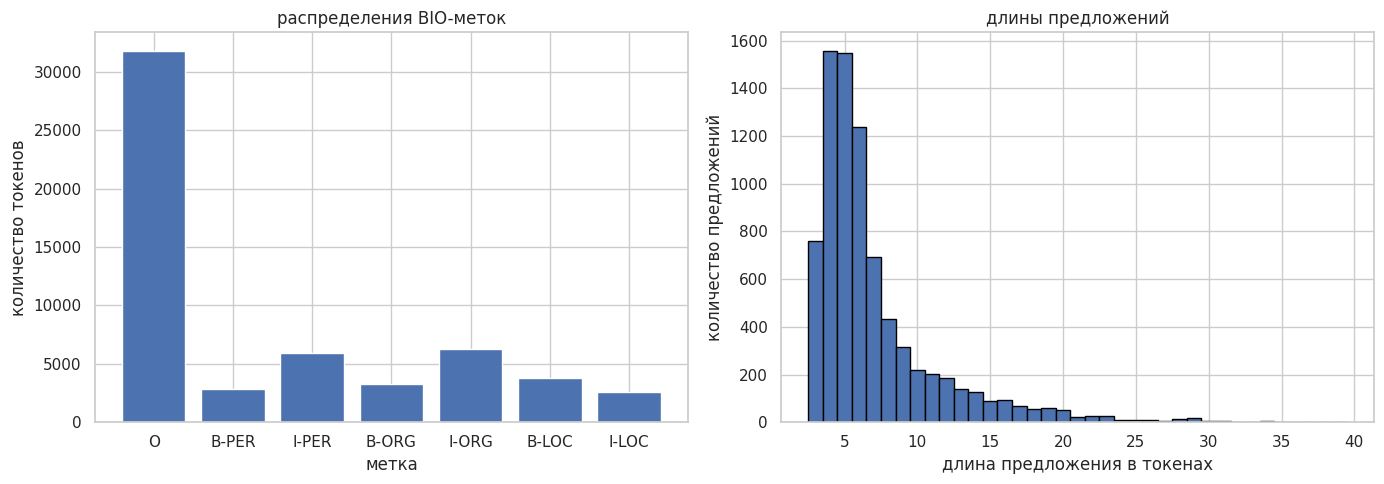

Доля: 56.38%


In [8]:
# ✍️ ВАШ КОД (задание 1.1)
# 1) bar plot распределения BIO-меток

all_tags = [id2label[t] for row in raw["train"]["ner_tags"] for t in row]
tag_counts = pd.Series(all_tags).value_counts().reindex(label_names, fill_value=0)
sentence_lengths = [len(tokens) for tokens in raw["train"]["tokens"]]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(label_names, [tag_counts[label] for label in label_names])
axes[0].set_xlabel("метка")
axes[0].set_ylabel("количество токенов")
axes[0].set_title("распределения BIO-меток")

# 2) гистограмма длины предложений в токенах

bins = np.arange(min(sentence_lengths) - 0.5, max(sentence_lengths) + 1.5, 1)
axes[1].hist(sentence_lengths, bins=bins, edgecolor="black")
axes[1].set_xlabel("длина предложения в токенах")
axes[1].set_ylabel("количество предложений")
axes[1].set_title("длины предложений")
plt.tight_layout()
plt.show()

# 3) доля токенов с меткой "O"
o_share = tag_counts["O"] / len(all_tags)
print(f"Доля: {o_share:.2%}")

### 💬 Задание 1.2. Выводы (впишите ответ ниже)

Ответьте своими словами, обязательно опираясь на числа, полученные в вашем эксперименте.

1. Какова доля токенов с меткой `O`? Какой тип сущностей (PER, ORG или LOC) встречается реже всего?
2. Что можно сказать о распределении длин предложений? Есть ли большинство коротких или длинных предложений, встречаются ли выбросы?
3. Почему при такой доле токенов `O` token-level accuracy плохо отражает качество модели NER? На какую метрику следует ориентироваться вместо нее и почему?

> *Ваш ответ:*
>
> 1. Доля токенов с меткой "O" 56,38%, Персоны встречаются реже всего
> 2. Распределение длин - пик около длины 5. Длинный хвост, вплоть до 30-35 предложений. Чем больше длина - тем меньше предложений
> 3. Потому что модель, которая будет всегда предсказывать "O" получит token-level accuracy 56%. Лучше подойдёт F1 на уровне сущеностей, т.к. объедениет и precicion и recall

## 2. Токенизация и выравнивание меток (1 балл)

В датасете BIO-метки заданы на уровне слов, тогда как BERT работает с подсловными токенами (subwords). Поэтому перед обучением необходимо перенести метки слов на последовательность подсловных токенов.

В ячейке ниже приведена готовая функция, которая выполняет это выравнивание. Разберитесь, как она работает: в задании 2.1 вам потребуется объяснить ее логику своими словами.

In [9]:
tokenizer = AutoTokenizer.from_pretrained(MODEL)

def align_labels_with_tokens(labels, word_ids):
  """Переносит пословные BIO-метки на subwords."""
  new_labels = []
  prev_word = None
  for word_id in word_ids:
      if word_id is None: # спецтокены [CLS] / [SEP] / паддинг
          new_labels.append(-100)
      elif word_id != prev_word: # первый subword нового слова
          new_labels.append(labels[word_id])
      else: # продолжение того же слова
          new_labels.append(-100)
      prev_word = word_id
  return new_labels

def tokenize_and_align(batch):
  tok = tokenizer(batch["tokens"], truncation=True, is_split_into_words=True, max_length=128)
  tok["labels"] = [align_labels_with_tokens(labels, tok.word_ids(batch_index=i)) for i, labels in enumerate(batch["ner_tags"])]
  return tok

tokenized = raw.map(tokenize_and_align, batched=True, remove_columns=raw["train"].column_names)
data_collator = DataCollatorForTokenClassification(tokenizer)

# Демонстрация на примере
example = raw["train"][1]
enc = tokenizer(example["tokens"], is_split_into_words=True)
aligned = align_labels_with_tokens(example["ner_tags"], enc.word_ids())
print(f'{"токен":<16}{"метка":<10}')
for tok_str, lab in zip(tokenizer.convert_ids_to_tokens(enc["input_ids"]), aligned):
  print(f'{tok_str:<16}{("-100" if lab == -100 else id2label[lab]):<10}')

config.json:   0%|          | 0.00/693 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/401 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.08M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.74M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/8000 [00:00<?, ? examples/s]

токен           метка     
[CLS]           -100      
Картина         O         
была            O         
привезен        O         
##а             -100      
из              O         
Флоренции       B-LOC     
в               O         
Мюнхен          B-LOC     
после           O         
почти           O         
двадцати        O         
##летних        -100      
переговоров     O         
и               O         
многих          O         
усилий          O         
вы              O         
##зволи         -100      
##ть            -100      
её              O         
у               O         
прежних         O         
владельцев      O         
.               O         
[SEP]           -100      


### 💬 Задание 2.1. Вопрос на понимание (впишите ответ ниже)

Изучите вывод примера выше и ответьте своими словами (3— 5 предложений):

1. Почему метка сущности присваивается только первому subword слова, а остальные получают значение `-100`?
2. Какую роль играет значение `-100` при обучении модели? Почему его также используют для специальных токенов `[CLS]` и `[SEP]`?
3. Какие проблемы возникли бы, если бы метку слова присваивали всем его subwords?

> *Ваш ответ:* 1. Чтобы каждому оцениваемому слову соответсвовал только 1 ответ
2. позиции с -100 не влияют на расчёт ошибки обучения, спец токены также не должны влиять, поэтому им также присваевается -100
3. Слова разбитые на несколько частей сильнее бы влияли на ошибку обучения + метки начала слова и продолжение необходимо было бы переразмечать

## 3. Дообучение модели (2 балла)

Для оценки качества модели в задаче NER используются метрики на уровне сущностей (entity-level), которые вычисляются с помощью библиотеки seqeval. Сущность считается распознанной правильно только в том случае, если модель верно определила и ее границы, и ее тип.

Функция ниже будет вычислять precision, recall и F1 после каждой эпохи обучения. Используйте ее без изменений.

In [10]:
def compute_metrics(eval_pred):
  logits, labels = eval_pred
  preds = np.argmax(logits, axis=-1)

  true_tags, pred_tags = [], []
  for pred_row, label_row in zip(preds, labels):
      tt, pp = [], []
      for p_i, l_i in zip(pred_row, label_row):
          if l_i == -100:
              continue
          tt.append(id2label[l_i])
          pp.append(id2label[p_i])
      true_tags.append(tt)
      pred_tags.append(pp)

  return {
      "precision": seq_precision(true_tags, pred_tags),
      "recall":    seq_recall(true_tags, pred_tags),
      "f1":        seq_f1(true_tags, pred_tags),
  }

### ✍️ Задание 3.1. Дообучите модель

1. Загрузите модель с помощью `AutoModelForTokenClassification.from_pretrained`, указав корректные значения `num_labels`, `id2label` и `label2id`.
2. Настройте `TrainingArguments`: оценка на валидационной выборке после каждой эпохи; 3–4 эпохи обучения; `batch_size=16`; `learning_rate=5e-5`; `seed=RANDOM_STATE`.
3. Создайте `Trainer`, передав обучающую и валидационную выборки, `data_collator`, `compute_metrics` и остальные необходимые параметры, затем запустите обучение с помощью `trainer.train()`.

Во время обучения значение eval_f1 должно постепенно расти.

Сохраните объект `Trainer` в переменную `trainer` —  он понадобится в следующих заданиях.

In [13]:
# ✍️ ВАШ КОД (задание 3.1)
model = AutoModelForTokenClassification.from_pretrained(
    MODEL,
    num_labels=len(label_names),
    id2label=id2label,
    label2id=label2id,
)

training_args = TrainingArguments(
    output_dir="ner_rubert_tiny2",
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    num_train_epochs=4,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    learning_rate=5e-5,
    seed=RANDOM_STATE,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    save_total_limit=2,
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized["train"],
    eval_dataset=tokenized["validation"],
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

trainer.train()

model.safetensors: reconstructing file:   0%|          |  0.00B /  118MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params we

Epoch,Training Loss,Validation Loss,Precision,Recall,F1
1,0.562130,0.299116,0.695271,0.731541,0.712945
2,0.267577,0.241684,0.749155,0.800562,0.774006
3,0.207019,0.233453,0.772866,0.813804,0.792807
4,0.176223,0.230205,0.776847,0.818620,0.797186


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=2000, training_loss=0.30323746871948243, metrics={'train_runtime': 44.6687, 'train_samples_per_second': 716.385, 'train_steps_per_second': 44.774, 'total_flos': 11948271939552.0, 'train_loss': 0.30323746871948243, 'epoch': 4.0})

## 4. Метрики token-level и entity-level (2 балла)

Функция ниже запускает обученную модель на указанном датасете и возвращает две последовательности строковых меток: истинные и предсказанные. Они уже приведены к формату, который можно напрямую использовать для вычисления как entity-level-метрик с помощью seqeval, так и token-level-метрик с помощью sklearn.

Это позволит сравнить оба подхода к оценке качества модели и понять, почему в задаче NER они могут давать заметно разные результаты.

In [14]:
def get_tags(trainer, dataset):
  out = trainer.predict(dataset)
  preds = np.argmax(out.predictions, axis=-1)
  labels = out.label_ids

  true_tags, pred_tags = [], []
  for pred_row, label_row in zip(preds, labels):
      tt, pp = [], []
      for p_i, l_i in zip(pred_row, label_row):
          if l_i == -100:
              continue
          tt.append(id2label[l_i])
          pp.append(id2label[p_i])
      true_tags.append(tt)
      pred_tags.append(pp)
  return true_tags, pred_tags

### ✍️ Задание 4.1. Сравните две оценки на тестовой выборке

1. Получите последовательности истинных и предсказанных меток для тестовой выборки.
2. Выведите entity-level-отчет с помощью `seq_classification_report(true_tags, pred_tags, digits=3)`.
3. Выведите token-level-отчет. Для этого разделите обе последовательности в плоские списки и передайте их в `sk_classification_report(...)`.

In [15]:
# ✍️ ВАШ КОД (задание 4.1)

true_tags, pred_tags = get_tags(trainer, tokenized["test"])

print("отчёт entity-level:")
print(seq_classification_report(true_tags, pred_tags, digits=3))

true_tags_flat = [tag for sentence in true_tags for tag in sentence]
pred_tags_flat = [tag for sentence in pred_tags for tag in sentence]

print("отчёт token-level:")
print(sk_classification_report(
    true_tags_flat,
    pred_tags_flat,
    digits=3,
    zero_division=0,
))



отчёт entity-level:
              precision    recall  f1-score   support

         LOC      0.792     0.831     0.811       893
         ORG      0.642     0.701     0.670       836
         PER      0.883     0.917     0.900       698

   micro avg      0.764     0.811     0.787      2427
   macro avg      0.772     0.816     0.794      2427
weighted avg      0.766     0.811     0.788      2427

отчёт token-level:
              precision    recall  f1-score   support

       B-LOC      0.841     0.858     0.849       893
       B-ORG      0.801     0.788     0.794       836
       B-PER      0.920     0.921     0.921       698
       I-LOC      0.869     0.770     0.817       601
       I-ORG      0.870     0.847     0.858      1675
       I-PER      0.947     0.957     0.952      1521
           O      0.965     0.976     0.971      8103

    accuracy                          0.929     14327
   macro avg      0.887     0.874     0.880     14327
weighted avg      0.929     0.929     

### 💬 Задание 4.2 — объясните разрыв (впишите ответ ниже)

Задание 4.2. Объясните различия между двумя оценками

Ответьте своими словами, обязательно используя значения из двух полученных отчетов.

1. Чему равны token-level accuracy и entity-level F1? Насколько они отличаются?
2. Назовите две причины, по которым token-level accuracy оказывается заметно выше.
3. Какую из этих двух оценок вы бы использовали как основную характеристику качества NER-модели и почему?

> *Ваш ответ:*
>
> 1. token-level accuracy 0.929 entity-level F1 0.787, разница 14%
> 2. 1) На уровне сущностей ошибка даже в одном слове делает сущность неверно распознанной, а на уровне токенов каждый правильный ответ засчитывается отдельно 2)  в тестовой выборке метку "O" имеет долю 56%, модель его хорошо распознает и таким образом повышается accuracy на уровне токенов
> 3. entity-level-F1, т.к. задача заключается именно в извлечении сущеностей, а не отдельных токенов

## 5. Анализ ошибок по сущностям (2 балла)

Функция `get_tags` возвращает метки на уровне слов в том же порядке, в котором слова представлены в `raw["test"]["tokens"]`. Благодаря этому каждому слову соответствует ровно одна истинная и одна предсказанная метка, поэтому слова и теги можно сопоставлять напрямую при анализе ошибок модели.

### ✍️ Задание 5.1. Найдите и выведите ошибки модели

Просмотрите предложения тестовой выборки и найдите те, в которых предсказанные метки (`pred_tags`) отличаются от истинных (`true_tags`).

Выведите не менее трех таких предложений. Для каждого покажите:

- слово, в котором обнаружено расхождение;
- истинную метку;
- предсказанную метку;
- несколько соседних слов для контекста (до и после ошибки).

In [22]:
# ✍️ ВАШ КОД (задание 5.1)

def get_errors(tokens_rows, true_tags, pred_tags):
    shown = 0

    for sentence_idx, (words, true_row, pred_row) in enumerate(
        zip(tokens_rows, true_tags, pred_tags)
    ):
        if true_row == pred_row:
            continue

        shown += 1
        print(f"индекс в test: {sentence_idx}")
        print("Предложение:", " ".join(words))

        for i, (word, true_tag, pred_tag) in enumerate(zip(words, true_row, pred_row)):
            if true_tag == pred_tag:
                continue

            # Берём до трёх соседних слов с каждой стороны
            context = 3
            left = max(0, i - context)
            right = min(len(words), i + context + 1)
            context = words[left:right]
            context[i - left] = f"[{word}]"

            print(f"  Слово: {word}, Истинная: {true_tag}, Предсказанная: {pred_tag}")
            print("  Контекст:", " ".join(context))

        if shown >= 3:
            break
        print("\n")

get_errors(raw["test"]["tokens"], true_tags, pred_tags)

индекс в test: 0
Предложение: перенаправление Мост Богдана Хмельницкого
  Слово: Мост, Истинная: B-ORG, Предсказанная: B-PER
  Контекст: перенаправление [Мост] Богдана Хмельницкого
  Слово: Хмельницкого, Истинная: I-ORG, Предсказанная: I-PER
  Контекст: перенаправление Мост Богдана [Хмельницкого]


индекс в test: 2
Предложение: Лёгкая атлетика ( мужчины , бег на 110 метров с барьерами )
  Слово: (, Истинная: O, Предсказанная: I-ORG
  Контекст: Лёгкая атлетика [(] мужчины , бег
  Слово: мужчины, Истинная: B-ORG, Предсказанная: I-ORG
  Контекст: Лёгкая атлетика ( [мужчины] , бег на
  Слово: ,, Истинная: I-ORG, Предсказанная: O
  Контекст: атлетика ( мужчины [,] бег на 110
  Слово: бег, Истинная: I-ORG, Предсказанная: O
  Контекст: ( мужчины , [бег] на 110 метров
  Слово: на, Истинная: I-ORG, Предсказанная: O
  Контекст: мужчины , бег [на] 110 метров с
  Слово: 110, Истинная: I-ORG, Предсказанная: O
  Контекст: , бег на [110] метров с барьерами
  Слово: метров, Истинная: I-ORG, Предсказан

### 💬 Задание 5.2. Проанализируйте ошибки модели (впишите ответ ниже)

Опираясь на найденные вами примеры, ответьте на вопросы:

1. Отнесите найденные ошибки как минимум к двум разным типам: нарушение границ сущности, путаница типа между PER, ORG и LOC, пропуск сущности или ложное срабатывание.
2. Для каждого типа приведите конкретный пример из своего вывода.
Выберите один из наиболее часто встречающихся типов ошибок и объясните, почему он возникает. Объяснение должно быть связано с особенностями текста или данных (например, неоднозначностью контекста, похожими шаблонами, редкостью примеров и т.п.).

> *Ваш ответ:*
>
> 1. В примерах встречаются: путаница типа сущности, нарушение границ, частичный пропуск сущности
>

2. путаница типа сущности: Слово: "Либерии", Истинная: B-LOC, Предсказанная: B-PER

нарушение границ сущности: Слово: "(", Истинная: O, Предсказанная: I-ORG

частичный пропуск сущности
"бег на 110 метров с барьерами" имеют истинные метки I-ORG, при этом модель присваивает им O, в результате большая часть размеченной сущности остаётся нераспознанной

"Богдана Хмельницкого" - похоже на имя человека, хотя здесь входит в название моста

"Либерии" - модель могла излишне ориентироваться на контекст (слово "Президента", описание человека)

## 6. Вывод (2 балла)

### 💬 Задание 6.1. Вывод (впишите ответ ниже)

Напишите вывод объемом 5—8 предложений, опираясь на результаты своего эксперимента.

В выводе ответьте на следующие вопросы:

1. Какое значение entity-level F1 удалось получить? Какие типы сущностей (PER, ORG, LOC) распознаются лучше, а какие хуже? Подкрепите ответ результатами и предложите возможное объяснение.
2. Для каких задач такая модель уже может быть полезна? В каких сценариях ее качества пока недостаточно?
3. Какие ограничения были у проведенного эксперимента (например, шум разметки, размер обучающей выборки, размер модели, ограничение длины последовательности)? Назовите одно конкретное улучшение, которое, по вашему мнению, может повысить качество модели.

> *Ваш ответ:* ...
1.
F1 на уровне сущностей 78,7%. Лучше всего разспознает людей (F1 0.9), места (0,81), хуже - организации 0,67. Возможное объяснение - названия организаций часто связаны с локациями либо именами людей. Имена возможно имеют более узнаваемый шаблон
2. Модель можно использовать как вспомогательную для предварительного поиска сущностей, в дополнение к ручной обработке. Нельзя использовать для полностью автоматической работы

3. Метки в обучающей выборке не идеальны - даже на примере предложений из задания 5. Обучающая выборка маленькая - 8000 примеров. В первую очередь пересмотреть метки, во вторую - увеличить выборку


## Бонусное задание

> Бонусная часть не является обязательной к выполнению и не влияет на оценку за домашнее задание. Выполнив это задание, вы получите развернутую обратную связь в свободной форме. Здесь нет строгих критериев выполнения.

В основном задании вы дообучали всю модель: обновлялись веса и энкодера BERT, и классификационной головы. Однако существует более дешевый режим обучения —  заморозить энкодер и обучать только выходную голову поверх фиксированных контекстных представлений, которые вычисляет BERT.

Такой подход позволяет значительно сократить число обучаемых параметров и ускорить обучение, но обычно приводит к некоторой потере качества.

Проверьте это на практике: сравните полное дообучение модели с обучением только классификационной головы и оцените, насколько меняются качество и время обучения.

### ✍️ Задание Б1. Обучите модель с замороженным энкодером

1. Загрузите новую модель с помощью `AutoModelForTokenClassification.from_pretrained`, используя те же параметры, что и в блоке 3.
2. Заморозьте энкодер BERT: пройдите по `model_frozen.base_model.parameters()` и установите `requires_grad=False` для всех его параметров. Классификационная голова (`classifier`) должна остаться обучаемой.
3. Создайте новый объект `Trainer` (можно использовать те же `TrainingArguments`), обучите модель и сравните ее с моделью из основного задания: значение entity-level F1 на тестовой выборке и время обучения.

> *Подсказка.* Время обучения удобно измерить с помощью `time.time()` до и после вызова `trainer.train()`.

In [ ]:
# ✍️ ВАШ КОД (задание Б1)

### 💬 Задание Б2. Рефлексия (впишите ответ ниже)

Ответьте своими словами, опираясь на результаты своего эксперимента.

1. Как изменились entity-level F1 и время обучения после заморозки энкодера? Приведите оба значения.
2. Почему заморозка энкодера обычно сильнее влияет на качество в задаче NER, чем в задаче классификации всего текста?
3. В каких случаях вы бы все же предпочли обучать только классификационную голову?

> *Ваш ответ:*
>
> 1. ...
> 2. ...
> 3. ...